# Phase 3 — Supplier KPI Analysis
**Project:** Procurement KPI Analysis  
**Input:** `outputs/procurement_data_cleaned.csv` (from Phase 2)  
**Goal:** Calculate supplier KPIs on *eligible* records only, build a supplier scorecard, and draw conclusions.

| KPI | Eligibility flag | Records |
|---|---|---|
| Delivery duration | `Eligible_Delivery_KPI` | 634 |
| Defect rate | `Eligible_Defect_KPI` | 587 |
| Potential savings | `Eligible_Potential_Savings_Analysis` | 714 |
| Compliance | all orders | 777 |

## Step 1 — Load the cleaned data

In [1]:
import os
import pandas as pd
import matplotlib.pyplot as plt

os.makedirs("outputs/kpi", exist_ok=True)
pd.set_option("display.float_format", "{:,.2f}".format)

df = pd.read_csv("outputs/procurement_data_cleaned.csv")
df["Order_Date"] = pd.to_datetime(df["Order_Date"], format="%m/%d/%Y")
df["Delivery_Date"] = pd.to_datetime(df["Delivery_Date"], format="%m/%d/%Y")

print(df.shape)
df.head()

(777, 23)


,PO_ID,Supplier,Order_Date,Delivery_Date,Item_Category,Order_Status,Quantity,Unit_Price,Negotiated_Price,Defective_Units,...,Delivery_Before_Order,Cancelled_With_Delivery_Date,Delivery_Duration_Days,Invalid_Delivery_Duration,Savings_Per_Unit,Potential_Total_Savings,Defect_Rate_Pct,Eligible_Delivery_KPI,Eligible_Defect_KPI,Eligible_Potential_Savings_Analysis
0,PO-00001,Alpha_Inc,2023-10-17,2023-10-25,Office Supplies,Cancelled,1176,20.13,17.81,NaN,...,False,True,8.00,False,2.32,"2,728.32",NaN,False,False,False
1,PO-00002,Delta_Logistics,2022-04-25,2022-05-05,Office Supplies,Delivered,1509,39.32,37.34,235.00,...,False,False,10.00,False,1.98,"2,987.82",15.57,True,True,True
2,PO-00003,Gamma_Co,2022-01-26,2022-02-15,MRO,Delivered,910,95.51,92.26,41.00,...,False,False,20.00,False,3.25,"2,957.50",4.51,True,True,True
3,PO-00004,Beta_Supplies,2022-10-09,2022-10-28,Packaging,Delivered,1344,99.85,95.52,112.00,...,False,False,19.00,False,4.33,"5,819.52",8.33,True,True,True
4,PO-00005,Delta_Logistics,2022-09-08,2022-09-20,Raw Materials,Delivered,1180,64.07,60.53,171.00,...,False,False,12.00,False,3.54,"4,177.20",14.49,True,True,True


## Step 2 — Confirm eligibility counts match Phase 2

In [2]:
elig = pd.DataFrame({
    "Metric": ["Delivery duration", "Defect rate", "Potential savings"],
    "Eligible": [df.Eligible_Delivery_KPI.sum(),
                 df.Eligible_Defect_KPI.sum(),
                 df.Eligible_Potential_Savings_Analysis.sum()]
})
elig["Excluded"] = len(df) - elig["Eligible"]
elig

,Metric,Eligible,Excluded
0,Delivery duration,634,143
1,Defect rate,587,190
2,Potential savings,714,63


These should equal 634 / 587 / 714 from `kpi_eligibility_summary.csv`. If not, stop and investigate before continuing.

## Step 3 — Delivery KPI (average days from order to delivery)

In [3]:
delivery = (df[df.Eligible_Delivery_KPI]
            .groupby("Supplier")["Delivery_Duration_Days"]
            .agg(Orders="count", Avg_Days="mean", Median_Days="median")
            .round(1))
delivery

,Orders,Avg_Days,Median_Days
Supplier,,,
Alpha_Inc,104,10.50,11.00
Beta_Supplies,132,11.30,12.00
Delta_Logistics,135,10.80,11.00
Epsilon_Group,139,10.90,11.00
Gamma_Co,124,10.00,10.00


**Read this as:** lower is better. Look at how far apart the suppliers really are; a gap of less than a day is not a meaningful difference.

## Step 4 — Defect KPI (total defective units ÷ total units)

In [4]:
quality = (df[df.Eligible_Defect_KPI]
           .groupby("Supplier")
           .agg(Orders=("PO_ID", "count"),
                Defective_Units=("Defective_Units", "sum"),
                Units_Ordered=("Quantity", "sum")))
quality["Defect_Rate_Pct"] = (quality.Defective_Units / quality.Units_Ordered * 100).round(2)
quality

,Orders,Defective_Units,Units_Ordered,Defect_Rate_Pct
Supplier,,,,
Alpha_Inc,102,"2,489.00",109724,2.27
Beta_Supplies,119,"12,737.00",136048,9.36
Delta_Logistics,113,"17,448.00",121957,14.31
Epsilon_Group,129,"4,266.00",143632,2.97
Gamma_Co,124,"6,728.00",135633,4.96


A weighted rate (total defects ÷ total units) is used so large orders count more than small ones. Averaging row-level percentages would not.

## Step 5 — Potential savings (list price − negotiated price)

In [5]:
sav = df[df.Eligible_Potential_Savings_Analysis]

savings_supplier = sav.groupby("Supplier")["Potential_Total_Savings"].sum().round(0)
savings_category = sav.groupby("Item_Category")["Potential_Total_Savings"].sum().round(0).sort_values(ascending=False)
savings_pivot = sav.pivot_table(index="Supplier", columns="Item_Category",
                                values="Potential_Total_Savings", aggfunc="sum").round(0)

print("Total potential savings:", f"{sav.Potential_Total_Savings.sum():,.0f}")
savings_pivot

Total potential savings: 3,638,920


Item_Category,Electronics,MRO,Office Supplies,Packaging,Raw Materials
Supplier,,,,,
Alpha_Inc,"100,248.00","145,222.00","164,059.00","130,322.00","82,580.00"
Beta_Supplies,"181,585.00","159,148.00","196,796.00","127,146.00","166,278.00"
Delta_Logistics,"133,994.00","158,506.00","134,019.00","136,365.00","135,657.00"
Epsilon_Group,"170,976.00","231,924.00","169,217.00","136,468.00","79,419.00"
Gamma_Co,"85,044.00","185,303.00","95,971.00","142,013.00","190,661.00"


These are **potential** savings (price difference × quantity), not realised savings. Cancelled orders are already excluded by the eligibility flag.

## Step 6 — Compliance KPI (% of orders marked Yes)

In [6]:
compliance = (df.groupby("Supplier")["Compliance"]
              .apply(lambda s: (s == "Yes").mean() * 100)
              .round(1)
              .rename("Compliance_Pct"))
compliance

Supplier
Alpha_Inc         93.60
Beta_Supplies     75.60
Delta_Logistics   60.80
Epsilon_Group     98.20
Gamma_Co          86.00
Name: Compliance_Pct, dtype: float64

## Step 7 — Supplier scorecard

In [7]:
scorecard = pd.concat([
    delivery["Avg_Days"],
    quality["Defect_Rate_Pct"],
    compliance,
    savings_supplier.rename("Potential_Savings"),
], axis=1)

# Rank each KPI: 1 = best
ranks = pd.DataFrame({
    "Delivery_Rank":   scorecard.Avg_Days.rank(ascending=True),
    "Quality_Rank":    scorecard.Defect_Rate_Pct.rank(ascending=True),
    "Compliance_Rank": scorecard.Compliance_Pct.rank(ascending=False),
    "Savings_Rank":    scorecard.Potential_Savings.rank(ascending=False),
})

# Weights are a judgement call — change them and explain why
weights = {"Quality_Rank": 0.35, "Compliance_Rank": 0.30,
           "Delivery_Rank": 0.20, "Savings_Rank": 0.15}

ranks["Weighted_Rank_Score"] = sum(ranks[k] * w for k, w in weights.items())
scorecard = scorecard.join(ranks)
scorecard["Overall_Rank"] = scorecard.Weighted_Rank_Score.rank().astype(int)
scorecard = scorecard.sort_values("Overall_Rank")
scorecard.to_csv("outputs/kpi/supplier_scorecard.csv")
scorecard

,Avg_Days,Defect_Rate_Pct,Compliance_Pct,Potential_Savings,Delivery_Rank,Quality_Rank,Compliance_Rank,Savings_Rank,Weighted_Rank_Score,Overall_Rank
Supplier,,,,,,,,,,
Alpha_Inc,10.50,2.27,93.60,"622,431.00",2.00,1.00,2.00,5.00,2.10,1
Epsilon_Group,10.90,2.97,98.20,"788,003.00",4.00,2.00,1.00,2.00,2.10,1
Gamma_Co,10.00,4.96,86.00,"698,992.00",1.00,3.00,3.00,3.00,2.60,3
Beta_Supplies,11.30,9.36,75.60,"830,953.00",5.00,4.00,4.00,1.00,3.75,4
Delta_Logistics,10.80,14.31,60.80,"698,541.00",3.00,5.00,5.00,4.00,4.45,5


**Weights used:** quality 35%, compliance 30%, delivery 20%, savings 15%.  
Rationale: defects and compliance failures create direct cost and risk; delivery times are very similar across suppliers; savings depend largely on the items bought rather than supplier behaviour. Lower weighted score = better.

## Step 8 — Trend over time (quarterly)

In [8]:
df["Quarter"] = df["Order_Date"].dt.to_period("Q").astype(str)

q_trend = (df[df.Eligible_Defect_KPI]
           .groupby(["Quarter", "Supplier"])
           .agg(d=("Defective_Units", "sum"), u=("Quantity", "sum")))
q_trend["Defect_Rate_Pct"] = q_trend.d / q_trend.u * 100
defect_trend = q_trend["Defect_Rate_Pct"].unstack("Supplier")
defect_trend.round(2)

Supplier,Alpha_Inc,Beta_Supplies,Delta_Logistics,Epsilon_Group,Gamma_Co
Quarter,,,,,
2022Q1,2.16,9.59,8.71,2.37,4.95
2022Q2,2.16,9.63,15.03,3.15,5.08
2022Q3,2.59,10.15,14.45,3.12,5.11
2022Q4,2.03,9.64,14.89,2.85,4.61
2023Q1,2.25,7.82,15.52,3.10,4.79
2023Q2,5.30,10.64,15.04,2.87,5.16
2023Q3,1.82,8.58,15.26,3.32,4.99
2023Q4,2.16,10.08,14.46,2.80,5.07
2024Q1,NaN,NaN,12.74,NaN,5.27


## Step 9 — Charts

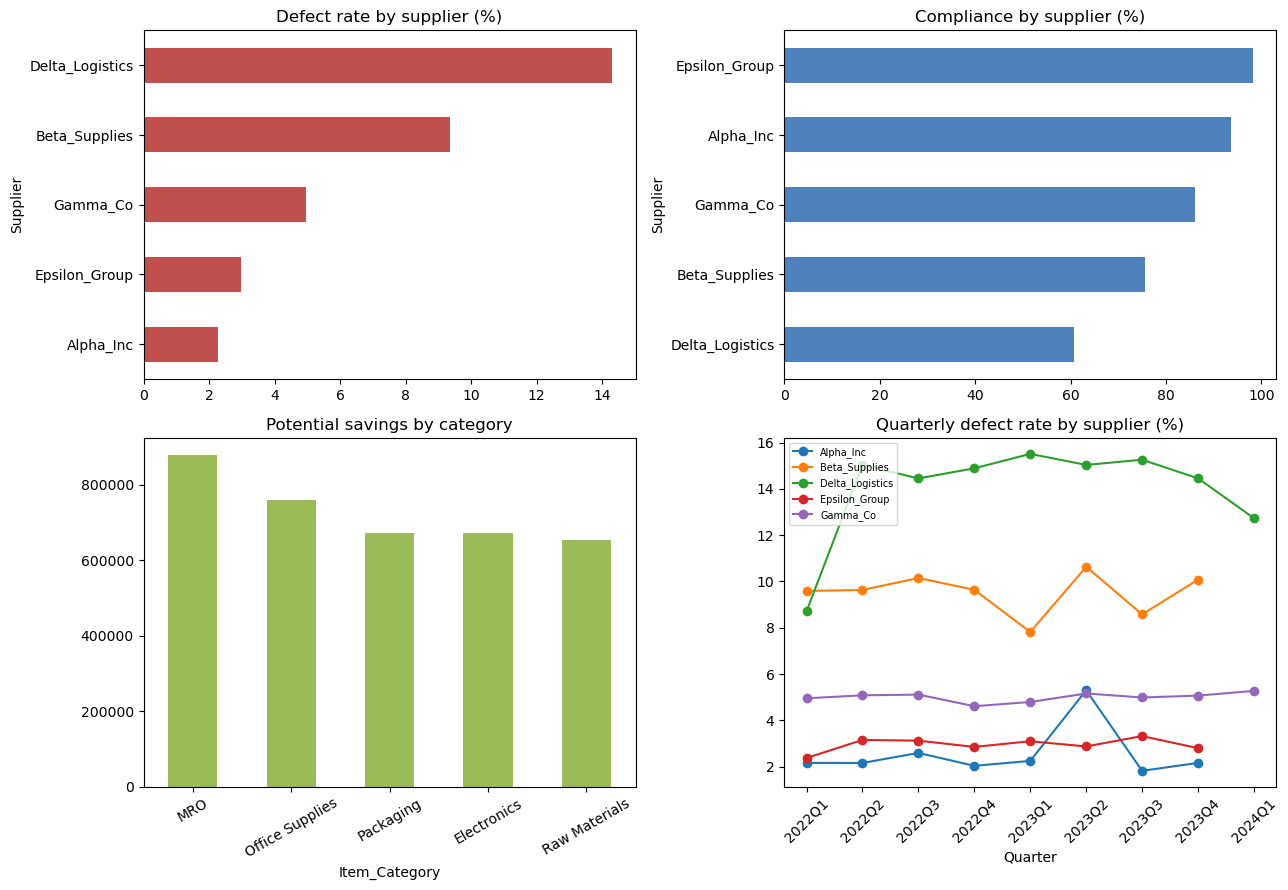

In [9]:
fig, ax = plt.subplots(2, 2, figsize=(13, 9))

quality.Defect_Rate_Pct.sort_values().plot.barh(ax=ax[0,0], color="#c0504d")
ax[0,0].set_title("Defect rate by supplier (%)")

compliance.sort_values().plot.barh(ax=ax[0,1], color="#4f81bd")
ax[0,1].set_title("Compliance by supplier (%)")

savings_category.plot.bar(ax=ax[1,0], color="#9bbb59")
ax[1,0].set_title("Potential savings by category")
ax[1,0].tick_params(axis="x", rotation=30)

defect_trend.plot(ax=ax[1,1], marker="o")
ax[1,1].set_title("Quarterly defect rate by supplier (%)")
ax[1,1].tick_params(axis="x", rotation=45)
ax[1,1].legend(fontsize=7)

plt.tight_layout()
plt.savefig("outputs/kpi/kpi_overview.png", dpi=150)
plt.show()

**Interpretation to write yourself:** which supplier stands out on each chart, and does the quarterly trend show improvement or deterioration?

## Step 10 — Category risk: where do defects concentrate?

In [10]:
cat_q = (df[df.Eligible_Defect_KPI]
         .groupby(["Supplier", "Item_Category"])
         .agg(d=("Defective_Units", "sum"), u=("Quantity", "sum")))
cat_q["Defect_Rate_Pct"] = (cat_q.d / cat_q.u * 100).round(2)
cat_q["Defect_Rate_Pct"].unstack("Item_Category")

Item_Category,Electronics,MRO,Office Supplies,Packaging,Raw Materials
Supplier,,,,,
Alpha_Inc,2.45,2.20,2.54,2.05,2.15
Beta_Supplies,8.19,10.15,9.73,9.86,8.91
Delta_Logistics,12.02,14.51,15.06,14.57,15.29
Epsilon_Group,3.33,3.00,3.13,2.84,2.16
Gamma_Co,4.86,5.03,5.06,5.00,4.86


## Step 11 — Compliance vs defects

In [11]:
non = df[df.Eligible_Defect_KPI].groupby("Compliance").agg(d=("Defective_Units","sum"), u=("Quantity","sum"))
non["Defect_Rate_Pct"] = (non.d / non.u * 100).round(2)
non

,d,u,Defect_Rate_Pct
Compliance,,,
No,"9,935.00",98769,10.06
Yes,"33,733.00",548225,6.15


Check whether non-compliant orders also have higher defect rates, or whether the two problems are independent.

## Step 12 — Export KPI tables

In [12]:
delivery.to_csv("outputs/kpi/delivery_kpi.csv")
quality.to_csv("outputs/kpi/defect_kpi.csv")
savings_pivot.to_csv("outputs/kpi/savings_supplier_category.csv")
compliance.to_csv("outputs/kpi/compliance_kpi.csv")
defect_trend.to_csv("outputs/kpi/defect_trend_quarterly.csv")
print(sorted(os.listdir("outputs/kpi")))

['compliance_kpi.csv', 'defect_kpi.csv', 'defect_trend_quarterly.csv', 'delivery_kpi.csv', 'kpi_overview.png', 'savings_supplier_category.csv', 'supplier_scorecard.csv']


## Step 13 — Findings, recommendations, limitations
### Findings 
Finding 1: Delivery times are nearly equal across suppliers (10 to 11.3 days), so they are not a differentiator.
Finding 2: Delta_Logistics has the highest defect rate (14.3%) and lowest compliance (60.8%), and the rate has stayed high since 2022Q2.
Finding 3: Alpha_Inc and Epsilon_Group combine low defects (under 3%) with high compliance (above 93%).
### Recommendation:
put Delta_Logistics on a corrective-action plan, review Beta_Supplies, and consider shifting volume to Alpha_Inc and Epsilon_Group.
**Limitations**
- 68 delivered orders have no delivery date and are excluded from delivery metrics.
- 136 orders have missing defect counts; these are excluded, not assumed to be zero.
- PO-00101 has a delivery date before its order date and is excluded.
- Savings are potential (list vs negotiated price), not realised.